# Sequence composition

How much of a sequence is G or C when some bases are unobserved? The denominator matters as much as the numerator.

A window with four observed positions and four N calls carries half as much observed sequence as a complete eight-base window. Report both coverage and GC among the observed A, C, G and T bases. Keep an entirely unobserved window missing.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

ACGTGCGC known 8 GC 0.75
NNNNAATT known 4 GC 0.0
GCGCGCAT known 8 GC 0.75
NNNNNNNN known 0 GC nan


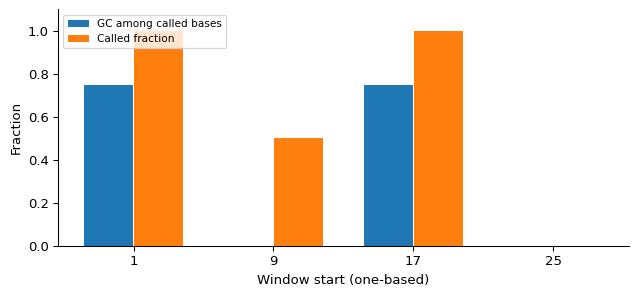

In [2]:
sequence = "ACGTGCGCNNNNAATTGCGCGCATNNNNNNNN"
width = 8
windows = [sequence[i : i + width] for i in range(0, len(sequence), width)]
gc = []
coverage = []
for w in windows:
    counts = Counter(w)
    known = sum(counts[c] for c in "ACGT")
    gc.append((counts["G"] + counts["C"]) / known if known else np.nan)
    coverage.append(known / len(w))
    print(w, "known", known, "GC", round(gc[-1], 3))
assert np.isnan(gc[-1])
x = np.arange(len(windows))
fig, ax = plt.subplots(figsize=(6.6, 3), constrained_layout=True)
ax.bar(x - 0.18, gc, 0.35, label="GC among called bases")
ax.bar(x + 0.18, coverage, 0.35, label="Called fraction")
ax.set(
    xticks=x,
    xticklabels=[str(i * width + 1) for i in x],
    xlabel="Window start (one-based)",
    ylabel="Fraction",
    ylim=(0, 1.1),
)
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The absent GC bar in the last window means that no bases were called. Its coverage is zero.

## Exercise

Replace an A with N in the second window, then calculate both fractions by hand.

## References

[Biopython, GC fraction and ambiguous bases](https://biopython.org/docs/latest/api/Bio.SeqUtils.html)